In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
nama_kelas = list(iris.target_names)

df = X.copy()
df["species"] = y.map(dict(enumerate(nama_kelas)))

print("Jumlah baris:", df.shape[0])
print("Jumlah fitur:", X.shape[1])
print("\nLima data pertama:")
display(df.head())
print("\nJumlah data per kelas:")
display(df["species"].value_counts())

Jumlah baris: 150
Jumlah fitur: 4

Lima data pertama:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Jumlah data per kelas:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

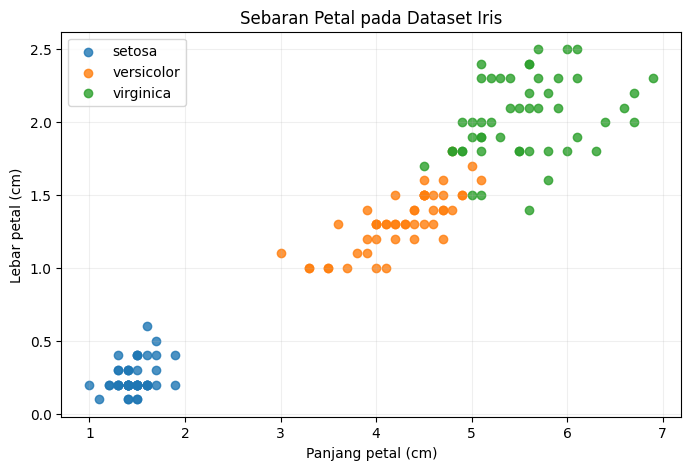

In [3]:
plt.figure(figsize=(8, 5))
for kelas in nama_kelas:
    bagian = df[df["species"] == kelas]
    plt.scatter(
        bagian["petal length (cm)"],
        bagian["petal width (cm)"],
        label=kelas,
        alpha=0.8
    )
plt.xlabel("Panjang petal (cm)")
plt.ylabel("Lebar petal (cm)")
plt.title("Sebaran Petal pada Dataset Iris")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Data training:", len(X_train))
print("Data testing :", len(X_test))

Data training: 120
Data testing : 30


In [5]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
print("Model Decision Tree berhasil dilatih.")

Model Decision Tree berhasil dilatih.


In [6]:
y_pred = model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)

print(f"Akurasi: {akurasi:.2%}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=nama_kelas, digits=3))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:")
print(cm)

Akurasi: 96.67%

Classification report:
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30

Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


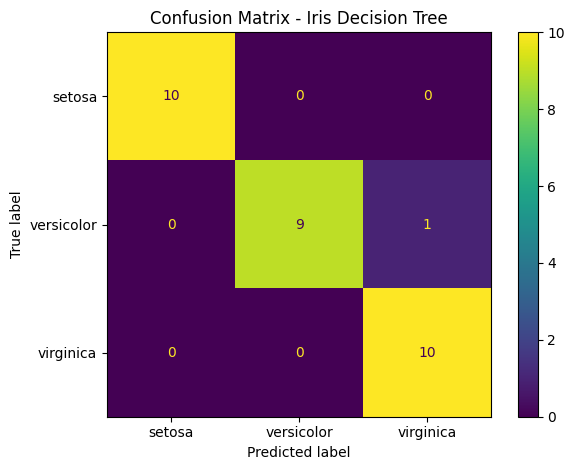

In [7]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nama_kelas)
disp.plot(values_format="d")
plt.title("Confusion Matrix - Iris Decision Tree")
plt.tight_layout()
plt.show()

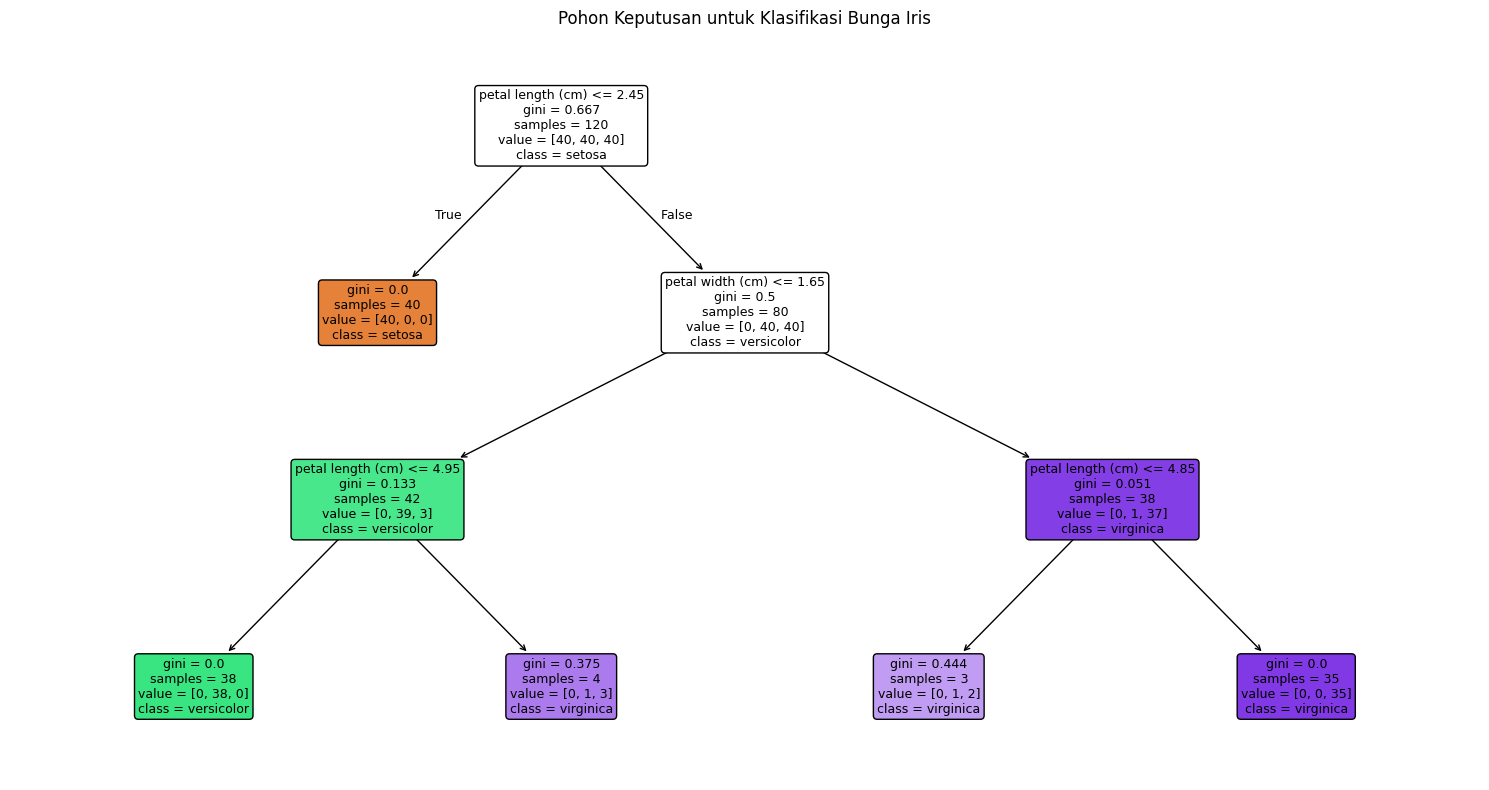

In [8]:
plt.figure(figsize=(15, 8))
plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=nama_kelas,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Pohon Keputusan untuk Klasifikasi Bunga Iris")
plt.tight_layout()
plt.show()


In [9]:
bunga_baru = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)
prediksi = model.predict(bunga_baru)[0]
probabilitas = model.predict_proba(bunga_baru)[0]

display(bunga_baru)
print("Prediksi jenis bunga:", nama_kelas[prediksi])
print("\nProbabilitas model:")
for nama, nilai in zip(nama_kelas, probabilitas):
    print(f"{nama}: {nilai:.1%}")

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Prediksi jenis bunga: setosa

Probabilitas model:
setosa: 100.0%
versicolor: 0.0%
virginica: 0.0%
